# Olist: customer segments, late delivery vs reviews, distance vs delay
**Phase 4 notebook** for business questions **Q2** (do late deliveries lower review scores?), **Q3** (does distance
explain delays?) and **Q4** (which customer segments should marketing target?).

- Data is read from the MySQL **views** of the clean layer (`sql/03_clean_layer.sql`), so the accepted data rules
  (README "Data rules") apply here exactly as in SQL.
- Every numeric result is saved to `outputs/`, every chart to `images/`. Money is in **R$ (BRL)**.
- Run top to bottom (`Kernel → Restart & Run All`). Random steps use a fixed seed, so results repeat exactly.

## 0. Setup
Imports, the database connection (credentials come from `.env`), and two helpers: one to read a query into pandas, one to save a result to `outputs/`.

In [1]:
import sys
from decimal import Decimal
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
from scipy import stats
from sqlalchemy import text

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(PROJECT_ROOT / "src"))
from load_to_mysql import get_engine          # same .env-based connection as the SQL scripts

OUTPUTS = PROJECT_ROOT / "outputs"
IMAGES = PROJECT_ROOT / "images"
IMAGES.mkdir(exist_ok=True)
RANDOM_SEED = 42
engine = get_engine(database="olist")


def read_view(sql):
    """Run a query and return a DataFrame. MySQL DECIMAL arrives as Python Decimal, so convert it to float."""
    with engine.connect() as connection:
        frame = pd.read_sql(text(sql), connection)
    for column in frame.columns:
        if frame[column].map(lambda value: isinstance(value, Decimal)).any():
            frame[column] = frame[column].astype(float)
    return frame


def save_output(frame, name):
    frame.to_csv(OUTPUTS / f"{name}.csv", index=False)
    print(f"saved outputs/{name}.csv ({len(frame)} rows)")

**Chart style.** One consistent look for every chart: a light surface, recessive grid, no top/right borders, left-aligned
titles. Colours come from a colour-blind-validated palette: **blue** is the main series, **orange** the second series.

In [2]:
BLUE, ORANGE = "#2a78d6", "#eb6834"
TEXT, TEXT_SECONDARY, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
BLUE_RAMP = LinearSegmentedColormap.from_list("blue_ramp", ["#cde2fb", "#86b6ef", "#2a78d6", "#104281"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": TEXT_SECONDARY, "text.color": TEXT,
    "xtick.color": TEXT_SECONDARY, "ytick.color": TEXT_SECONDARY,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
})


def add_source(ax, source_text):
    """Small grey source line under the chart, so every chart says where its numbers come from."""
    ax.annotate(f"Source: {source_text}", xy=(0, -0.17), xycoords="axes fraction",
                fontsize=8, color=TEXT_SECONDARY, ha="left", va="top")


def save_chart(fig, name):
    fig.savefig(IMAGES / f"{name}.png")
    plt.show()
    plt.close(fig)
    print(f"saved images/{name}.png")

## 1. RFM customer segmentation (Q4, user story US-05)
**RFM** scores each customer (`customer_unique_id`) on three things:
- **Recency (R):** days since their last order, counted to the day after the last purchase in the analysis window.
  Fewer days = more recent = **higher** score.
- **Frequency (F):** number of valid orders.
- **Monetary (M):** total product revenue in R$ (same definition as the KPI Total Revenue, excluding freight).

**Why not quintiles for Frequency?** 96.97 % of customers have exactly one order (`outputs/retention_orders_per_customer.csv`).
`pd.qcut(frequency, 5)` needs 5 groups of equal size, but the 20 %, 40 %, 60 % and 80 % cut points are all "1 order", so the
bin edges are duplicates and qcut raises an error. The next cell shows that error, then uses fixed bins instead:
**F = 1 / 2 / 3** for **1 / 2 / 3+ orders**. R and M have many distinct values, so they use **quintiles** (scores 1-5).

> **Predict before running:** what share of all customers will land in the two "Lost" segments (one order, bought long ago)?
> And will the repeat-customer segments hold a bigger share of revenue than of customers?

In [3]:
customers = read_view("""
    SELECT customer_unique_id,
           MAX(purchase_date)  AS last_purchase_date,
           COUNT(*)            AS frequency,
           SUM(order_revenue)  AS monetary_brl
    FROM v_orders_valid
    GROUP BY customer_unique_id
""")
customers["last_purchase_date"] = pd.to_datetime(customers["last_purchase_date"])
reference_date = customers["last_purchase_date"].max() + pd.Timedelta(days=1)
customers["recency_days"] = (reference_date - customers["last_purchase_date"]).dt.days
print(f"customers: {len(customers):,}   reference date: {reference_date.date()}")

# Show why quintiles cannot be used for Frequency
try:
    pd.qcut(customers["frequency"], 5)
except ValueError as error:
    print("pd.qcut on frequency fails:", str(error).splitlines()[0])

customers: 94,703   reference date: 2018-08-30
pd.qcut on frequency fails: Bin edges must be unique: Index([1.0, 1.0, 1.0, 1.0, 1.0, 16.0], dtype='float64', name='frequency').


In [4]:
# R: quintiles of recency, most recent fifth = 5.   M: quintiles of spend, highest fifth = 5.
customers["r_score"] = pd.qcut(customers["recency_days"], 5, labels=[5, 4, 3, 2, 1]).astype(int)
customers["m_score"] = pd.qcut(customers["monetary_brl"], 5, labels=[1, 2, 3, 4, 5]).astype(int)
# F: fixed bins, because 97 % of customers have one order
customers["f_score"] = pd.cut(customers["frequency"], bins=[0, 1, 2, np.inf], labels=[1, 2, 3]).astype(int)

# Document the score boundaries (US-05 AC-3)
recency_bins = customers.groupby("r_score")["recency_days"].agg(["min", "max", "count"]).reset_index()
recency_bins.insert(0, "dimension", "recency_days")
monetary_bins = customers.groupby("m_score")["monetary_brl"].agg(["min", "max", "count"]).reset_index()
monetary_bins.insert(0, "dimension", "monetary_brl")
frequency_bins = customers.groupby("f_score")["frequency"].agg(["min", "max", "count"]).reset_index()
frequency_bins.insert(0, "dimension", "frequency_orders")
score_bins = pd.concat([recency_bins.rename(columns={"r_score": "score"}),
                        frequency_bins.rename(columns={"f_score": "score"}),
                        monetary_bins.rename(columns={"m_score": "score"})])
score_bins = score_bins.rename(columns={"min": "min_value", "max": "max_value", "count": "customers"})
save_output(score_bins, "rfm_score_bins")
score_bins

saved outputs/rfm_score_bins.csv (13 rows)


,dimension,score,min_value,max_value,customers
0,recency_days,1,383.00,602.0,18903
1,recency_days,2,270.00,382.0,18710
2,recency_days,3,179.00,269.0,19005
3,recency_days,4,94.00,178.0,19093
4,recency_days,5,1.00,93.0,18992
0,frequency_orders,1,1.00,1.0,91829
1,frequency_orders,2,2.00,2.0,2639
2,frequency_orders,3,3.00,16.0,235
0,monetary_brl,1,0.85,39.9,19592
1,monetary_brl,2,39.91,69.9,19674


**Segments for a mostly one-time customer base.** Classic RFM names (Champions, Loyal, At Risk …) assume many repeat
buyers. Here 97 % bought once, so the useful question for marketing is: *which one-time buyers are worth a second-purchase
campaign?* The rules, in order:

| Segment | Rule | Suggested action |
|---|---|---|
| Loyal (3+ orders) | F = 3 | VIP perks; protect their delivery experience |
| Repeat - active | F = 2 and R ≥ 3 | Cross-sell related categories |
| Repeat - lapsing | F = 2 and R ≤ 2 | Win-back offer before they drift away |
| New - high value | F = 1, R ≥ 4, M ≥ 4 | **Priority:** second-purchase nurture while still recent |
| New - standard | F = 1, R ≥ 4, M ≤ 3 | Low-cost second-purchase email, free-shipping threshold |
| One-time - cooling | F = 1, R = 3 | Reminder with recommendations |
| Lost - high value | F = 1, R ≤ 2, M ≥ 4 | Targeted win-back for the most valuable lapsed buyers |
| Lost - low value | F = 1, R ≤ 2, M ≤ 3 | Low priority: newsletter only |

In [5]:
SEGMENT_ORDER = ["Loyal (3+ orders)", "Repeat - active", "Repeat - lapsing", "New - high value",
                 "New - standard", "One-time - cooling", "Lost - high value", "Lost - low value"]
SEGMENT_ACTION = {
    "Loyal (3+ orders)": "VIP perks; protect their delivery experience",
    "Repeat - active": "Cross-sell related categories",
    "Repeat - lapsing": "Win-back offer before they drift away",
    "New - high value": "Priority: second-purchase nurture while still recent",
    "New - standard": "Low-cost second-purchase email, free-shipping threshold",
    "One-time - cooling": "Reminder with recommendations",
    "Lost - high value": "Targeted win-back for the most valuable lapsed buyers",
    "Lost - low value": "Low priority: newsletter only",
}


def assign_segment(row):
    if row.f_score == 3:
        return "Loyal (3+ orders)"
    if row.f_score == 2:
        return "Repeat - active" if row.r_score >= 3 else "Repeat - lapsing"
    # From here on: one-time buyers (F = 1)
    if row.r_score >= 4:
        return "New - high value" if row.m_score >= 4 else "New - standard"
    if row.r_score == 3:
        return "One-time - cooling"
    return "Lost - high value" if row.m_score >= 4 else "Lost - low value"


customers["segment"] = customers.apply(assign_segment, axis=1)

segments = (customers.groupby("segment")
            .agg(customers=("customer_unique_id", "count"),
                 revenue_brl=("monetary_brl", "sum"),
                 avg_recency_days=("recency_days", "mean"),
                 avg_orders=("frequency", "mean"),
                 avg_monetary_brl=("monetary_brl", "mean"))
            .reindex(SEGMENT_ORDER).reset_index())
segments["pct_of_customers"] = (100 * segments["customers"] / segments["customers"].sum()).round(2)
segments["revenue_share_pct"] = (100 * segments["revenue_brl"] / segments["revenue_brl"].sum()).round(2)
segments["suggested_action"] = segments["segment"].map(SEGMENT_ACTION)
segments = segments.round({"revenue_brl": 2, "avg_recency_days": 1, "avg_orders": 2, "avg_monetary_brl": 2})
segments = segments[["segment", "customers", "pct_of_customers", "revenue_brl", "revenue_share_pct",
                     "avg_recency_days", "avg_orders", "avg_monetary_brl", "suggested_action"]]

# US-05 AC-1: every customer has exactly one segment, and the segments add up to the total
assert segments["customers"].sum() == len(customers) == customers["customer_unique_id"].nunique()
assert customers["segment"].isna().sum() == 0
save_output(segments, "rfm_segments")

# Customer-level scores go to MySQL (not committed as a CSV) for the Power BI RFM page
customers[["customer_unique_id", "recency_days", "frequency", "monetary_brl", "r_score", "f_score", "m_score", "segment"]] \
    .to_sql("rfm_customer_segments", engine, if_exists="replace", index=False)
print("wrote MySQL table olist.rfm_customer_segments")
segments

saved outputs/rfm_segments.csv (8 rows)


wrote MySQL table olist.rfm_customer_segments


,segment,customers,pct_of_customers,revenue_brl,revenue_share_pct,avg_recency_days,avg_orders,avg_monetary_brl,suggested_action
0,Loyal (3+ orders),235,0.25,99399.59,0.74,202.0,3.4,422.98,VIP perks; protect their delivery experience
1,Repeat - active,1690,1.78,419688.18,3.12,134.3,2.0,248.34,Cross-sell related categories
2,Repeat - lapsing,949,1.00,228036.95,1.70,382.7,2.0,240.29,Win-back offer before they drift away
3,New - high value,14737,15.56,3953859.18,29.40,93.0,1.0,268.29,Priority: second-purchase nurture while still ...
4,New - standard,22110,23.35,1231834.92,9.16,90.8,1.0,55.71,"Low-cost second-purchase email, free-shipping ..."
5,One-time - cooling,18388,19.42,2397203.13,17.82,221.7,1.0,130.37,Reminder with recommendations
6,Lost - high value,13793,14.56,3843804.37,28.58,394.3,1.0,278.68,Targeted win-back for the most valuable lapsed...
7,Lost - low value,22801,24.08,1275703.36,9.49,395.1,1.0,55.95,Low priority: newsletter only


## 2. Hypothesis test: do late deliveries lower review scores? (Q2, US-02)
**Unit of analysis: one row per `review_id`** (Rule 2). A few surveys cover several orders; counting such a review once per
order would count one customer's opinion several times and overstate the sample size. A review is **late** if *any* of its
orders arrived after the estimated date. Only delivered orders in delivery scope (`v_order_delivery`) are used.

- **H0:** review scores of late and on-time orders come from the same distribution.
- **H1:** they differ (two-sided test; we do not assume the direction in advance).
- **Test: Mann-Whitney U.** Scores are 1-5 stars: ordinal, heavily tied and far from normal, so a t-test's assumptions do
  not fit. Mann-Whitney compares ranks instead of means.
- **Effect size: rank-biserial correlation** r = 2U/(n_late × n_on_time) − 1, from −1 to +1. Negative = late reviews tend
  to score lower. With ~95 K reviews almost any difference is "significant", so the effect size says whether it **matters**.
  Rule of thumb for |r|: < 0.1 negligible, 0.1-0.3 small, 0.3-0.5 medium, ≥ 0.5 large.
- **Bootstrap 95 % CI** for the difference in mean score (late − on-time): resample each group with replacement 10,000 times,
  take the middle 95 % of the differences. Managers think in "stars", so this gives the gap in stars with a range.
- **Sensitivity check:** some surveys were created *before* the order arrived (`outputs/dq_review_timing.csv`). Those
  customers may be scoring a parcel they have not received yet. Re-run without them and see whether the answer changes.

> **Predict before running:** will the effect size be negligible, small, medium or large? And will the gap in stars get
> bigger or smaller when reviews created before delivery are removed?

In [6]:
review_orders = read_view("""
    SELECT r.review_id, r.order_id, r.review_score, r.review_creation_date,
           d.order_delivered_customer_date, d.is_late
    FROM v_order_delivery AS d
    JOIN v_order_reviews_dedup AS r ON r.order_id = d.order_id
""")

# One row per review_id (Rule 2)
reviews = (review_orders.groupby("review_id")
           .agg(review_score=("review_score", "first"),
                distinct_scores=("review_score", "nunique"),
                is_late=("is_late", "max"),                     # late if ANY linked order was late
                late_status_values=("is_late", "nunique"),
                linked_orders=("order_id", "count"),
                review_creation_date=("review_creation_date", "first"),
                last_delivered_date=("order_delivered_customer_date", "max"))
           .reset_index())
assert (reviews["distinct_scores"] == 1).all()                  # one review = one score

print(f"order-level rows: {len(review_orders):,}   ->   one row per review: {len(reviews):,}")
print(f"reviews covering 2+ orders: {(reviews.linked_orders > 1).sum():,}   "
      f"of which late and on-time orders mixed: {(reviews.late_status_values > 1).sum():,}")
print(reviews["is_late"].value_counts().rename({0: "on time", 1: "late"}).to_string())

order-level rows: 95,558   ->   one row per review: 95,066
reviews covering 2+ orders: 483   of which late and on-time orders mixed: 39
is_late
on time    88701
late        6365


In [7]:
def effect_size_label(rank_biserial):
    size = abs(rank_biserial)
    return "negligible" if size < 0.1 else "small" if size < 0.3 else "medium" if size < 0.5 else "large"


def compare_late_vs_on_time(review_table, analysis_name, bootstrap_samples=10_000):
    """Mann-Whitney U + rank-biserial effect size + bootstrap 95 % CI for mean(late) - mean(on time)."""
    late_scores = review_table.loc[review_table["is_late"] == 1, "review_score"].to_numpy()
    on_time_scores = review_table.loc[review_table["is_late"] == 0, "review_score"].to_numpy()
    n_late, n_on_time = len(late_scores), len(on_time_scores)

    u_late, p_value = stats.mannwhitneyu(late_scores, on_time_scores, alternative="two-sided")
    rank_biserial = 2 * u_late / (n_late * n_on_time) - 1

    random_generator = np.random.default_rng(RANDOM_SEED)
    mean_differences = np.empty(bootstrap_samples)
    for sample_number in range(bootstrap_samples):
        late_resample = random_generator.choice(late_scores, size=n_late, replace=True)
        on_time_resample = random_generator.choice(on_time_scores, size=n_on_time, replace=True)
        mean_differences[sample_number] = late_resample.mean() - on_time_resample.mean()
    ci_low, ci_high = np.percentile(mean_differences, [2.5, 97.5])

    return {
        "analysis": analysis_name,
        "n_late_reviews": n_late,
        "n_on_time_reviews": n_on_time,
        "mean_score_late": round(late_scores.mean(), 3),
        "mean_score_on_time": round(on_time_scores.mean(), 3),
        "mean_difference_late_minus_on_time": round(late_scores.mean() - on_time_scores.mean(), 3),
        "bootstrap_ci95_low": round(ci_low, 3),
        "bootstrap_ci95_high": round(ci_high, 3),
        "bootstrap_samples": bootstrap_samples,
        "mann_whitney_u_late": u_late,
        "p_value": p_value,
        "rank_biserial": round(rank_biserial, 3),
        "effect_size": effect_size_label(rank_biserial),
        # Same information as a probability: a random on-time review scores higher than a random late one (ties count half)
        "prob_on_time_scores_higher": round(1 - u_late / (n_late * n_on_time), 3),
    }


# Sensitivity: drop reviews whose survey was created before the (last) order was delivered (date level)
created_before_delivery = (reviews["review_creation_date"].dt.normalize()
                           < reviews["last_delivered_date"].dt.normalize())
print(f"reviews created before delivery (excluded in the sensitivity check): {created_before_delivery.sum():,}")

test_results = pd.DataFrame([
    compare_late_vs_on_time(reviews, "main: all reviews, one row per review_id"),
    compare_late_vs_on_time(reviews[~created_before_delivery], "sensitivity: excluding reviews created before delivery"),
])
save_output(test_results, "hypothesis_test_results")
test_results.T

reviews created before delivery (excluded in the sensitivity check): 4,960


saved outputs/hypothesis_test_results.csv (2 rows)


,0,1
analysis,"main: all reviews, one row per review_id",sensitivity: excluding reviews created before ...
n_late_reviews,6365,1624
n_on_time_reviews,88701,88482
mean_score_late,2.271,3.531
mean_score_on_time,4.293,4.294
mean_difference_late_minus_on_time,-2.022,-0.763
bootstrap_ci95_low,-2.06,-0.835
bootstrap_ci95_high,-1.983,-0.691
bootstrap_samples,10000,10000
mann_whitney_u_late,102014716.0,50086852.5


**Plain-English conclusion.** Built from the numbers above (not typed by hand) and saved to `outputs/hypothesis_test_conclusion.txt` for the memo. Line 2 reports the sensitivity check honestly: if it changes the size of the effect, the manager needs to know.

In [8]:
main, sensitivity = test_results.iloc[0], test_results.iloc[1]
# Late reviews removed by the sensitivity check = late reviews written before the parcel arrived
late_reviews_before_delivery = main.n_late_reviews - sensitivity.n_late_reviews
p_text = "p < 0.001" if main.p_value < 0.001 else f"p = {main.p_value:.3f}"
conclusion = (
    f"Late deliveries cost about {abs(main.mean_difference_late_minus_on_time):.2f} stars per review "
    f"({main.mean_score_late:.2f} vs {main.mean_score_on_time:.2f} out of 5; 95% CI "
    f"{abs(main.bootstrap_ci95_high):.2f} to {abs(main.bootstrap_ci95_low):.2f} stars), and this is not chance ({p_text}).\n"
    f"But {late_reviews_before_delivery / main.n_late_reviews:.0%} of late reviews were written before the parcel arrived; counting only "
    f"reviews written after delivery, the gap is smaller but still real: {abs(sensitivity.mean_difference_late_minus_on_time):.2f} stars "
    f"({sensitivity.effect_size} effect, 95% CI {abs(sensitivity.bootstrap_ci95_high):.2f} to {abs(sensitivity.bootstrap_ci95_low):.2f})."
)
(OUTPUTS / "hypothesis_test_conclusion.txt").write_text(conclusion + "\n")
print(conclusion)

Late deliveries cost about 2.02 stars per review (2.27 vs 4.29 out of 5; 95% CI 1.98 to 2.06 stars), and this is not chance (p < 0.001).
But 74% of late reviews were written before the parcel arrived; counting only reviews written after delivery, the gap is smaller but still real: 0.76 stars (medium effect, 95% CI 0.69 to 0.83).


## 3. Distance vs delay (Q3)
Does a longer seller → customer distance mean slower or later deliveries?
- **Coordinates:** `v_geo_by_zip` (mean lat/lng per zip prefix, duplicates removed, points outside Brazil ignored).
- **Distance:** the **haversine** formula: the straight-line ("as the crow flies") distance on a sphere of radius 6,371 km.
  Real road distance is longer, but the ranking of near vs far is what matters here.
- **One row per order.** If an order has items from several sellers, use the **farthest** seller: the order is complete only
  when the last parcel arrives. Orders with a zip prefix missing from geolocation are dropped (count printed).
- **Spearman correlation (ρ)** works on ranks, so it is not distorted by very long distances or a few very slow deliveries.
  It is computed against delivery days (purchase → delivery) and against the late flag (0/1).
- **Late % by distance band**, which a manager can read without knowing what ρ means.

> **Predict before running:** will distance correlate more strongly with *delivery days* or with *being late*? Why might
> they differ? (Hint: who sets the estimated delivery date, and does it already know the distance?)

In [9]:
order_seller_rows = read_view("""
    SELECT DISTINCT d.order_id, i.seller_id, d.delivery_days, d.is_late,
           customer_geo.latitude AS customer_lat, customer_geo.longitude AS customer_lng,
           seller_geo.latitude   AS seller_lat,   seller_geo.longitude   AS seller_lng
    FROM v_order_delivery AS d
    JOIN customers   AS c ON c.customer_id = d.customer_id
    JOIN order_items AS i ON i.order_id    = d.order_id
    JOIN sellers     AS s ON s.seller_id   = i.seller_id
    LEFT JOIN v_geo_by_zip AS customer_geo ON customer_geo.zip_code_prefix = c.customer_zip_code_prefix
    LEFT JOIN v_geo_by_zip AS seller_geo   ON seller_geo.zip_code_prefix   = s.seller_zip_code_prefix
""")

EARTH_RADIUS_KM = 6371.0


def haversine_km(latitude_1, longitude_1, latitude_2, longitude_2):
    """Great-circle distance in km between two points given in degrees (works on whole columns at once)."""
    latitude_1, longitude_1, latitude_2, longitude_2 = map(np.radians, (latitude_1, longitude_1, latitude_2, longitude_2))
    half_chord = (np.sin((latitude_2 - latitude_1) / 2) ** 2
                  + np.cos(latitude_1) * np.cos(latitude_2) * np.sin((longitude_2 - longitude_1) / 2) ** 2)
    return 2 * EARTH_RADIUS_KM * np.arcsin(np.sqrt(half_chord))


has_coordinates = order_seller_rows[["customer_lat", "customer_lng", "seller_lat", "seller_lng"]].notna().all(axis=1)
orders_without_coordinates = order_seller_rows.loc[~has_coordinates, "order_id"].nunique()
order_seller_rows = order_seller_rows[has_coordinates].copy()
order_seller_rows["distance_km"] = haversine_km(order_seller_rows.seller_lat, order_seller_rows.seller_lng,
                                                order_seller_rows.customer_lat, order_seller_rows.customer_lng)

order_distance = (order_seller_rows.groupby("order_id")
                  .agg(distance_km=("distance_km", "max"),          # farthest seller
                       sellers=("seller_id", "nunique"),
                       delivery_days=("delivery_days", "first"),
                       is_late=("is_late", "first"))
                  .reset_index())
print(f"orders with distance: {len(order_distance):,}   dropped (zip missing from geolocation): {orders_without_coordinates:,}   "
      f"multi-seller orders: {(order_distance.sellers > 1).sum():,}")

orders with distance: 95,724   dropped (zip missing from geolocation): 481   multi-seller orders: 1,262


In [10]:
correlation_rows = []
for outcome in ["delivery_days", "is_late"]:
    rho, p_value = stats.spearmanr(order_distance["distance_km"], order_distance[outcome])
    correlation_rows.append({"x": "distance_km", "y": outcome, "n_orders": len(order_distance),
                             "spearman_rho": round(rho, 3), "p_value": p_value})
distance_correlation = pd.DataFrame(correlation_rows)
save_output(distance_correlation, "distance_correlation")

DISTANCE_BANDS = [0, 100, 300, 600, 1000, 1500, np.inf]
BAND_LABELS = ["0-100", "100-300", "300-600", "600-1,000", "1,000-1,500", "1,500+"]   # km
order_distance["distance_band"] = pd.cut(order_distance["distance_km"], bins=DISTANCE_BANDS,
                                         labels=BAND_LABELS, right=False)
distance_bands = (order_distance.groupby("distance_band", observed=True)
                  .agg(orders=("order_id", "count"),
                       late_pct=("is_late", "mean"),
                       avg_delivery_days=("delivery_days", "mean"),
                       median_distance_km=("distance_km", "median"))
                  .reset_index())
distance_bands["late_pct"] = (100 * distance_bands["late_pct"]).round(2)
distance_bands["pct_of_orders"] = (100 * distance_bands["orders"] / distance_bands["orders"].sum()).round(2)
distance_bands = distance_bands.round({"avg_delivery_days": 2, "median_distance_km": 1})
save_output(distance_bands, "distance_vs_delay_bands")
display(distance_correlation)
distance_bands

saved outputs/distance_correlation.csv (2 rows)
saved outputs/distance_vs_delay_bands.csv (6 rows)


,x,y,n_orders,spearman_rho,p_value
0,distance_km,delivery_days,95724,0.541,0.000000e+00
1,distance_km,is_late,95724,0.069,1.331847e-100


,distance_band,orders,late_pct,avg_delivery_days,median_distance_km,pct_of_orders
0,0-100,17756,4.49,6.42,30.6,18.55
1,100-300,13276,5.20,9.92,199.1,13.87
2,300-600,31441,6.77,12.53,423.4,32.85
3,"600-1,000",17904,7.09,14.61,791.5,18.70
4,"1,000-1,500",6593,8.81,17.17,1213.1,6.89
5,"1,500+",8754,11.64,20.44,2120.1,9.15


## 4. Charts
Charts 1-4 and 7 read the **Phase 3 output files**, so each chart shows exactly the numbers cited from `outputs/`.
Charts 5-6 use the results computed above. Each PNG is saved to `images/`.

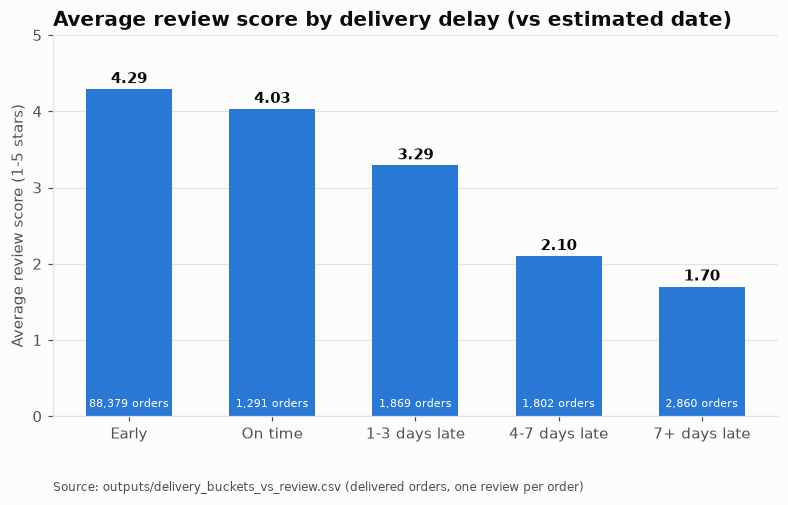

saved images/01_delay_bucket_vs_review.png


In [11]:
# Chart 1: delay bucket vs average review score
buckets = pd.read_csv(OUTPUTS / "delivery_buckets_vs_review.csv").sort_values("delay_bucket_order")
fig, ax = plt.subplots(figsize=(8.5, 4.5))
bars = ax.bar(buckets["delay_bucket"], buckets["avg_review_score"], color=BLUE, width=0.6)
for bar, score, orders in zip(bars, buckets["avg_review_score"], buckets["orders"]):
    ax.annotate(f"{score:.2f}", (bar.get_x() + bar.get_width() / 2, score), xytext=(0, 4),
                textcoords="offset points", ha="center", fontweight="bold")
    ax.annotate(f"{orders:,} orders", (bar.get_x() + bar.get_width() / 2, 0), xytext=(0, 6),
                textcoords="offset points", ha="center", fontsize=7, color="white")
ax.set_ylim(0, 5)
ax.set_ylabel("Average review score (1-5 stars)")
ax.set_title("Average review score by delivery delay (vs estimated date)")
ax.grid(axis="x", visible=False)
add_source(ax, "outputs/delivery_buckets_vs_review.csv (delivered orders, one review per order)")
save_chart(fig, "01_delay_bucket_vs_review")

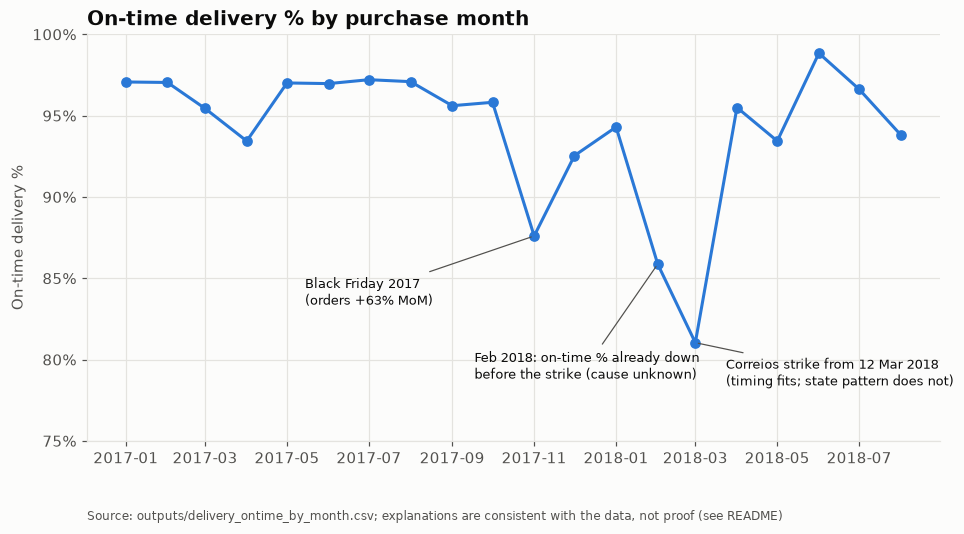

saved images/02_ontime_by_month.png


In [12]:
# Chart 2: on-time % by purchase month, with the spikes annotated
monthly = pd.read_csv(OUTPUTS / "delivery_ontime_by_month.csv", parse_dates=["purchase_month"])
revenue_by_month = pd.read_csv(OUTPUTS / "revenue_mom.csv", parse_dates=["purchase_month"]).set_index("purchase_month")
black_friday_order_growth = revenue_by_month["orders"].pct_change().loc["2017-11-01"]

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(monthly["purchase_month"], monthly["on_time_pct"], color=BLUE, linewidth=2, marker="o", markersize=6)
annotations = [
    ("2017-11-01", f"Black Friday 2017\n(orders +{black_friday_order_growth:.0%} MoM)", (-150, -45)),
    ("2018-02-01", "Feb 2018: on-time % already down\nbefore the strike (cause unknown)", (-120, -75)),
    ("2018-03-01", "Correios strike from 12 Mar 2018\n(timing fits; state pattern does not)", (20, -28)),
]
for month, note, offset in annotations:
    value = monthly.set_index("purchase_month").loc[month, "on_time_pct"]
    ax.annotate(note, xy=(pd.Timestamp(month), value), xytext=offset, textcoords="offset points", fontsize=8.5,
                color=TEXT, arrowprops=dict(arrowstyle="-", color=TEXT_SECONDARY, linewidth=0.8))
ax.set_ylim(75, 100)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_ylabel("On-time delivery %")
ax.set_title("On-time delivery % by purchase month")
add_source(ax, "outputs/delivery_ontime_by_month.csv; explanations are consistent with the data, not proof (see README)")
save_chart(fig, "02_ontime_by_month")

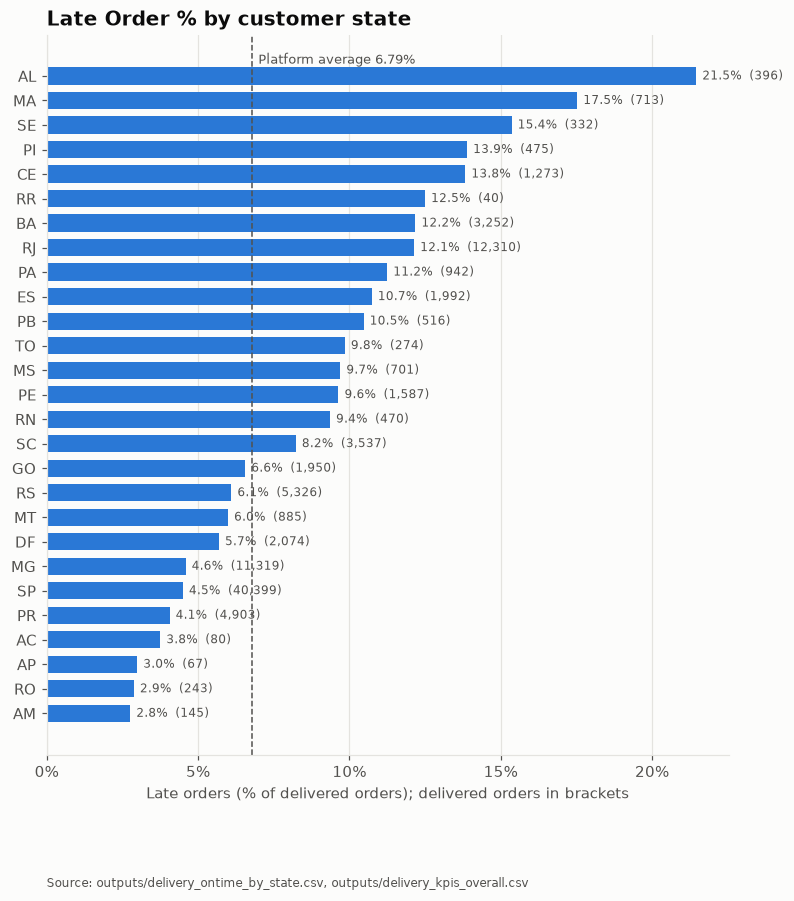

saved images/03_late_pct_by_state.png


In [13]:
# Chart 3: late % by customer state, with the platform average
states = pd.read_csv(OUTPUTS / "delivery_ontime_by_state.csv").sort_values("late_pct")
platform_late_pct = pd.read_csv(OUTPUTS / "delivery_kpis_overall.csv")["late_pct"].iloc[0]
fig, ax = plt.subplots(figsize=(8, 8.5))
ax.barh(states["customer_state"], states["late_pct"], color=BLUE, height=0.7)
for position, (late_pct, orders) in enumerate(zip(states["late_pct"], states["delivered_orders"])):
    ax.annotate(f"{late_pct:.1f}%  ({orders:,})", (late_pct, position), xytext=(4, 0), textcoords="offset points",
                va="center", fontsize=8, color=TEXT_SECONDARY)
ax.axvline(platform_late_pct, color=TEXT_SECONDARY, linestyle="--", linewidth=1)
ax.annotate(f"Platform average {platform_late_pct:.2f}%", (platform_late_pct, len(states) - 0.5), xytext=(4, 0),
            textcoords="offset points", fontsize=8.5, color=TEXT_SECONDARY)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_xlabel("Late orders (% of delivered orders); delivered orders in brackets")
ax.set_title("Late Order % by customer state")
ax.grid(axis="y", visible=False)
add_source(ax, "outputs/delivery_ontime_by_state.csv, outputs/delivery_kpis_overall.csv")
save_chart(fig, "03_late_pct_by_state")

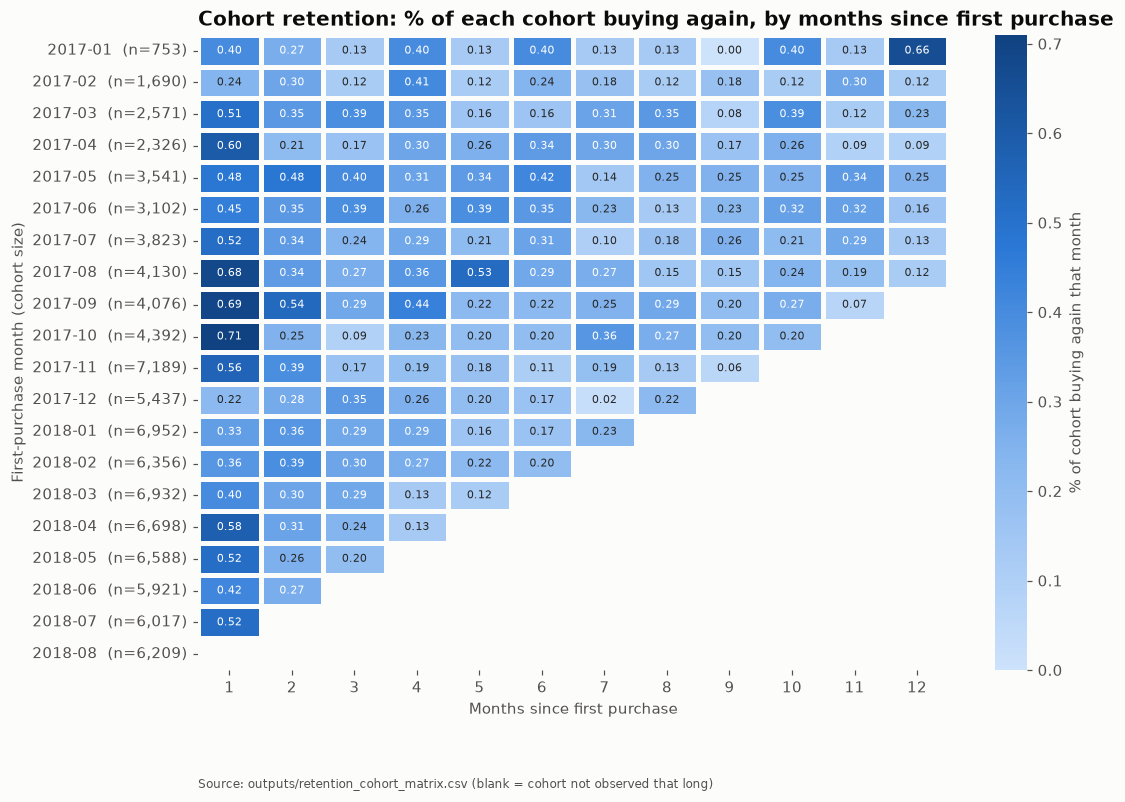

saved images/04_cohort_retention_heatmap.png


In [14]:
# Chart 4: cohort retention heatmap (months 1-12 after first purchase; blank = not observable yet)
matrix = pd.read_csv(OUTPUTS / "retention_cohort_matrix.csv", parse_dates=["cohort_month"])
matrix["cohort"] = matrix["cohort_month"].dt.strftime("%Y-%m") + "  (n=" + matrix["cohort_customers"].map("{:,}".format) + ")"
heatmap_values = matrix.set_index("cohort")[[f"m{month}" for month in range(1, 13)]]
heatmap_values.columns = range(1, 13)
fig, ax = plt.subplots(figsize=(11, 7.5))
sns.heatmap(heatmap_values, annot=True, fmt=".2f", annot_kws={"fontsize": 7.5}, cmap=BLUE_RAMP,
            linewidths=2, linecolor=SURFACE, cbar_kws={"label": "% of cohort buying again that month"}, ax=ax)
ax.set_xlabel("Months since first purchase")
ax.set_ylabel("First-purchase month (cohort size)")
ax.set_title("Cohort retention: % of each cohort buying again, by months since first purchase")
ax.grid(False)
add_source(ax, "outputs/retention_cohort_matrix.csv (blank = cohort not observed that long)")
save_chart(fig, "04_cohort_retention_heatmap")

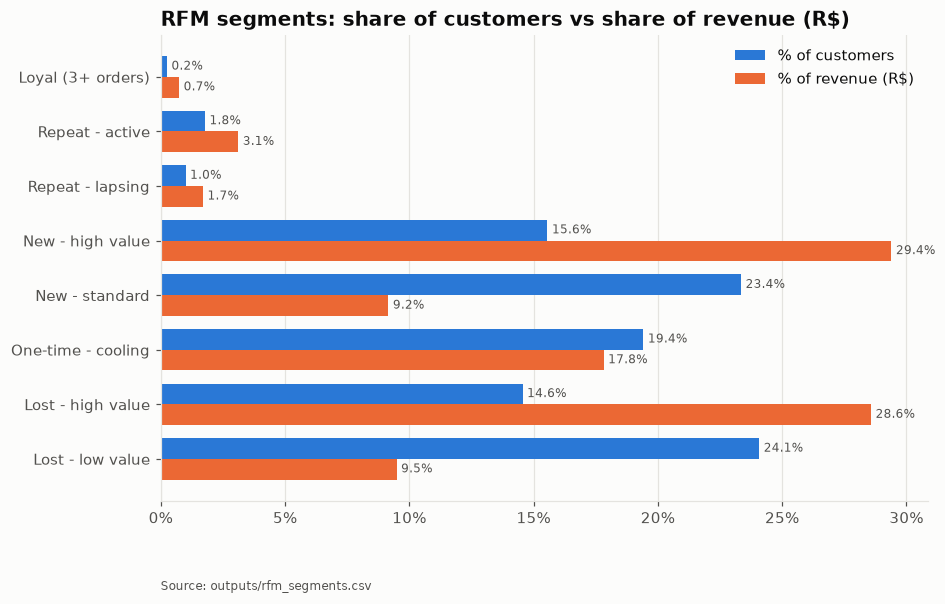

saved images/05_rfm_segments.png


In [15]:
# Chart 5: RFM segments, share of customers vs share of revenue (two series -> legend + direct labels)
fig, ax = plt.subplots(figsize=(9, 5.5))
positions = np.arange(len(segments))
bar_height = 0.38
ax.barh(positions - bar_height / 2, segments["pct_of_customers"], height=bar_height, color=BLUE, label="% of customers")
ax.barh(positions + bar_height / 2, segments["revenue_share_pct"], height=bar_height, color=ORANGE, label="% of revenue (R$)")
for position, (customer_pct, revenue_pct) in enumerate(zip(segments["pct_of_customers"], segments["revenue_share_pct"])):
    ax.annotate(f"{customer_pct:.1f}%", (customer_pct, position - bar_height / 2), xytext=(3, 0),
                textcoords="offset points", va="center", fontsize=8, color=TEXT_SECONDARY)
    ax.annotate(f"{revenue_pct:.1f}%", (revenue_pct, position + bar_height / 2), xytext=(3, 0),
                textcoords="offset points", va="center", fontsize=8, color=TEXT_SECONDARY)
ax.set_yticks(positions, segments["segment"])
ax.invert_yaxis()
ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_title("RFM segments: share of customers vs share of revenue (R$)")
ax.legend(loc="upper right", frameon=False)
ax.grid(axis="y", visible=False)
add_source(ax, "outputs/rfm_segments.csv")
save_chart(fig, "05_rfm_segments")

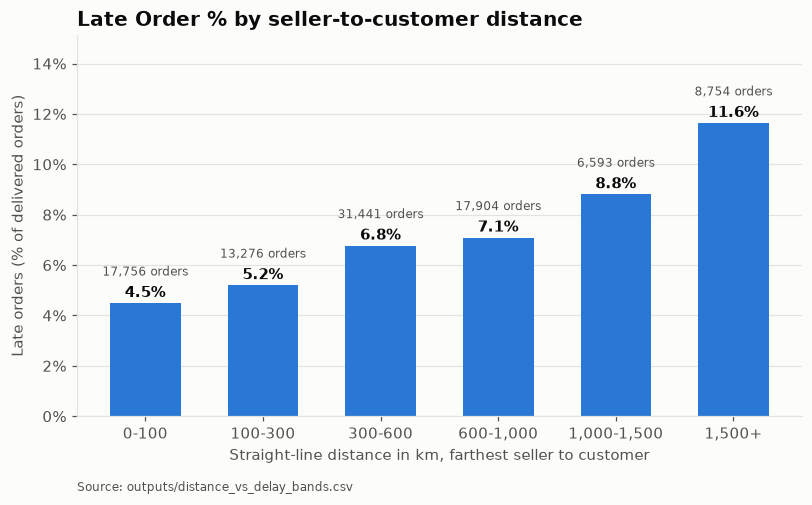

saved images/06_distance_vs_late_pct.png


In [16]:
# Chart 6: late % by seller -> customer distance band
fig, ax = plt.subplots(figsize=(8.5, 4.5))
bars = ax.bar(distance_bands["distance_band"].astype(str), distance_bands["late_pct"], color=BLUE, width=0.6)
for bar, late_pct, orders in zip(bars, distance_bands["late_pct"], distance_bands["orders"]):
    ax.annotate(f"{late_pct:.1f}%", (bar.get_x() + bar.get_width() / 2, late_pct), xytext=(0, 4),
                textcoords="offset points", ha="center", fontweight="bold")
    ax.annotate(f"{orders:,} orders", (bar.get_x() + bar.get_width() / 2, late_pct), xytext=(0, 18),
                textcoords="offset points", ha="center", fontsize=8, color=TEXT_SECONDARY)
ax.set_ylim(0, distance_bands["late_pct"].max() * 1.3)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
ax.set_ylabel("Late orders (% of delivered orders)")
ax.set_xlabel("Straight-line distance in km, farthest seller to customer")
ax.set_title("Late Order % by seller-to-customer distance")
ax.grid(axis="x", visible=False)
add_source(ax, "outputs/distance_vs_delay_bands.csv")
save_chart(fig, "06_distance_vs_late_pct")

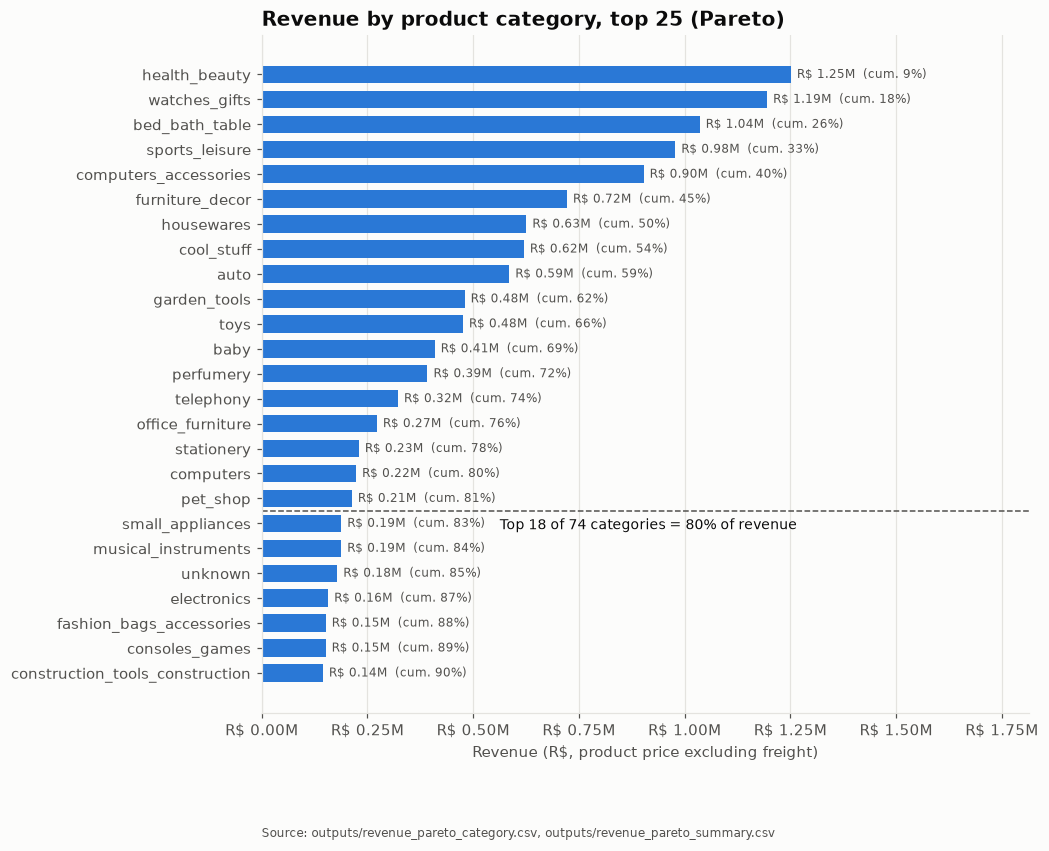

saved images/07_category_revenue_pareto.png


In [17]:
# Chart 7: category revenue Pareto (top 25 categories, R$), with the 80 % cut-off from the SQL summary
pareto = pd.read_csv(OUTPUTS / "revenue_pareto_category.csv").sort_values("revenue_rank").head(25)
pareto_summary = pd.read_csv(OUTPUTS / "revenue_pareto_summary.csv").set_index("dimension")
categories_for_80pct = int(pareto_summary.loc["product category", "members_for_80pct_revenue"])
total_categories = int(pareto_summary.loc["product category", "members"])

fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(pareto["category_english"], pareto["revenue_brl"], color=BLUE, height=0.7)
for position, (revenue, cumulative) in enumerate(zip(pareto["revenue_brl"], pareto["cumulative_pct"])):
    ax.annotate(f"R$ {revenue / 1e6:.2f}M  (cum. {cumulative:.0f}%)", (revenue, position), xytext=(4, 0),
                textcoords="offset points", va="center", fontsize=8, color=TEXT_SECONDARY)
ax.axhline(categories_for_80pct - 0.5, color=TEXT_SECONDARY, linestyle="--", linewidth=1)
ax.annotate(f"Top {categories_for_80pct} of {total_categories} categories = 80% of revenue",
            (pareto["revenue_brl"].max() * 0.45, categories_for_80pct - 0.5), xytext=(0, -12),
            textcoords="offset points", fontsize=9, color=TEXT)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda value, _: f"R$ {value / 1e6:.2f}M"))
ax.set_xlim(0, pareto["revenue_brl"].max() * 1.45)
ax.set_xlabel("Revenue (R$, product price excluding freight)")
ax.set_title("Revenue by product category, top 25 (Pareto)")
ax.grid(axis="y", visible=False)
add_source(ax, "outputs/revenue_pareto_category.csv, outputs/revenue_pareto_summary.csv")
save_chart(fig, "07_category_revenue_pareto")

## 5. Outputs from this notebook
| File | Contents |
|---|---|
| `outputs/rfm_score_bins.csv` | R / F / M score boundaries |
| `outputs/rfm_segments.csv` | Segment size, revenue (R$) and revenue share, suggested action |
| `outputs/hypothesis_test_results.csv` | Mann-Whitney U, p-value, rank-biserial, bootstrap CI (main + sensitivity) |
| `outputs/hypothesis_test_conclusion.txt` | 2-line manager summary |
| `outputs/distance_correlation.csv` | Spearman ρ, distance vs delivery days and vs late flag |
| `outputs/distance_vs_delay_bands.csv` | Late % and delivery days by distance band |
| `images/01` … `images/07` | Charts |
| MySQL `olist.rfm_customer_segments` | Customer-level RFM scores for Power BI (re-run this notebook after reloading the database) |